# Lecture 9 · Exercises

Code for [exercises.md](exercises.md)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

DATA = Path("../../coding_tasks/Data/Out_Data")
pd.set_option("display.width", 200)

Three helpers. `cells` is the table of group means every question starts from, `main_effect` is the one-line version of ME(A) from the notes, and `fit` prints a regression the way R's `summary` does.

In [2]:
def cells(frame, factors, value):
    return frame.groupby(factors, observed=True)[value].agg(["size", "mean"]).round(6)


def main_effect(frame, factor, value, control=0):
    hi = frame[value][frame[factor] != control].mean()
    lo = frame[value][frame[factor] == control].mean()
    return hi - lo


def fit(formula, frame):
    m = smf.ols(formula, data=frame).fit()
    out = pd.DataFrame({"est": m.params, "se": m.bse, "t": m.tvalues, "p": m.pvalues})
    print(out.round(6))
    print(f"\nresidual se = {np.sqrt(m.mse_resid):.4f} on {int(m.df_resid)} df")
    print(f"R2 = {m.rsquared:.4f}   adj = {m.rsquared_adj:.4f}   F = {m.fvalue:.2f}")
    return m

---

## Exercise 9.1 · Weight loss

Three components of a weight loss intervention, all 2³ combinations, control coded as −1.

**y is weight after minus weight before, in kg, so a negative value is weight lost.** Getting that backwards inverts every conclusion below.

In [3]:
wt = pd.read_csv(DATA / "lecture9_weight_loss.csv").rename(
    columns={"A": "diary", "B": "activity", "C": "visit"}
)
print(wt.shape, "| missing:", wt.isna().sum().sum())
cells(wt, ["diary", "activity", "visit"], "y")

(800, 5) | missing: 0


size      mean
diary activity visit                
-1    -1       -1      100  0.943238
                1      100  1.841243
       1       -1      100 -0.145396
                1      100 -1.108105
 1    -1       -1      100  0.978214
                1      100  2.463123
       1       -1      100 -0.487862
                1      100  0.399163

Renaming is not cosmetic. A column called `C` shadows patsy's categorical helper, so `smf.ols("y ~ C(A) * C(B) * C(C)")` dies with `TypeError: 'Series' object is not callable`. The R code in the sheet has no such clash.

### 1 · the mean effect of each treatment

In [4]:
for col in ["diary", "activity", "visit"]:
    print(f"ME({col:9s}) = {main_effect(wt, col, 'y', control=-1):+.7f}")

ME(diary    ) = +0.4554145
ME(activity ) = -1.8920048
ME(visit    ) = +0.5768074


Only **activity** reduces weight, by 1.89 kg. A food diary and a home visit are both associated with weight *gain* of roughly half a kilo.

The design is balanced at 100 per cell, so these raw differences are the main effects exactly.

### 2 · the long model

0/1 dummies reproduce R's `factor()` treatment contrasts exactly, and sidestep the name clash.

In [5]:
wd = wt.assign(
    a=(wt.diary == 1).astype(int),
    b=(wt.activity == 1).astype(int),
    c=(wt.visit == 1).astype(int),
)
mw = fit("y ~ a * b * c", wd)

                est        se         t         p
Intercept  0.943238  0.100150  9.418280  0.000000
a          0.034976  0.141633  0.246947  0.805013
b         -1.088635  0.141633 -7.686300  0.000000
a:b       -0.377441  0.200299 -1.884385  0.059879
c          0.898005  0.141633  6.340360  0.000000
a:c        0.586904  0.200299  2.930132  0.003486
b:c       -1.860714  0.200299 -9.289659  0.000000
a:b:c      1.262829  0.283266  4.458101  0.000009

residual se = 1.0015 on 792 df
R2 = 0.5565   adj = 0.5526   F = 141.99


Identical to the official output: residual se 1.001 on 792 df, R² 0.5565, F 142.

### 3 · interpreting the coefficients

Eight cells, eight coefficients, an exact re-parameterisation of the group means. The intercept is the all-control cell and each first-order term is an effect with the other two factors held at control.

In [6]:
base = wt.y[(wt.diary == -1) & (wt.activity == -1) & (wt.visit == -1)].mean()
only_c = wt.y[(wt.diary == -1) & (wt.activity == -1) & (wt.visit == 1)].mean()

print(f"all-control cell mean      = {base:.4f}   intercept = {mw.params['Intercept']:.4f}")
print(f"only-home-visit cell mean  = {only_c:.4f}")
print(f"intercept + beta_c         = {mw.params['Intercept'] + mw.params['c']:.4f}")
print("\nthe official solution gives this total as 1.74, but 0.94 + 0.89 = 1.83")
print("and the cell mean is 1.8412")

all-control cell mean      = 0.9432   intercept = 0.9432
only-home-visit cell mean  = 1.8412
intercept + beta_c         = 1.8412

the official solution gives this total as 1.74, but 0.94 + 0.89 = 1.83
and the cell mean is 1.8412


Almost every coefficient involving activity is negative, −1.089, −0.377 and −1.861, the only exception being the triple interaction at +1.263. That again points to activity as the treatment doing the work.

The three-way interaction is significant at p = 9.5e-06, which is why this dataset is set as the exercise. Dropping the highest-order term because it "looks insignificant" would be wrong here.

### What the question does not ask

Is the best combination simply all three treatments?

In [7]:
ranked = (
    wt.groupby(["diary", "activity", "visit"])["y"]
    .mean()
    .sort_values()
    .rename("mean y")
    .reset_index()
)
print(ranked.round(4).to_string(index=False))
print(f"\nbest cell      : {ranked.iloc[0]['mean y']:+.4f} kg")
print(f"all three on   : {wt.y[(wt.diary==1) & (wt.activity==1) & (wt.visit==1)].mean():+.4f} kg")

 diary  activity  visit  mean y
    -1         1      1 -1.1081
     1         1     -1 -0.4879
    -1         1     -1 -0.1454
     1         1      1  0.3992
    -1        -1     -1  0.9432
     1        -1     -1  0.9782
    -1        -1      1  1.8412
     1        -1      1  2.4631

best cell      : -1.1081 kg
all three on   : +0.3992 kg


No. Giving all three produces **+0.40 kg**, a gain. The best cell, at −1.11 kg, is activity plus home visit **without** the food diary, and adding the diary to that combination costs 1.51 kg of the result.

This is the whole argument for a factorial design. Three separate two-arm trials would have recovered the three main effects and pointed at activity alone, which is not the best option available. The information that beats it lives in the interactions, and separate trials cannot estimate those.

Note how far the home visit shifts. With no food diary it **gains** 0.90 kg on its own, and **loses** 0.96 kg once activity is added. Those two numbers are `c` and `c + b:c` in the table above, both of which hold the diary at its control level.

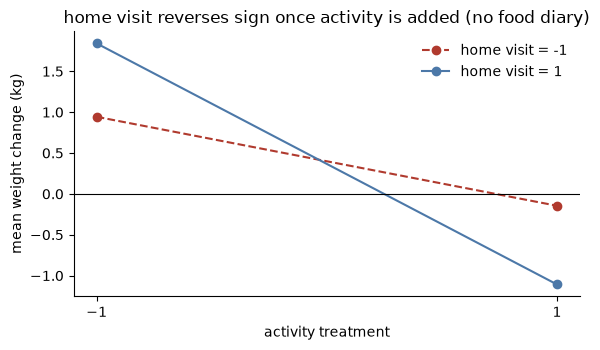

visit effect at activity = -1: +0.8980  (= beta_c)
visit effect at activity =  1: -0.9627  (= beta_c + beta_bc)


In [8]:
sub = wt[wt.diary == -1]
piv = sub.groupby(["activity", "visit"])["y"].mean().unstack()

fig, ax = plt.subplots(figsize=(6, 3.6))
for visit, colour, style in [(-1, "#B03A2E", "o--"), (1, "#4C78A8", "o-")]:
    ax.plot([-1, 1], piv[visit].values, style, color=colour, label=f"home visit = {visit}")

ax.axhline(0, color="black", lw=0.8)
ax.set_xticks([-1, 1])
ax.set_xlabel("activity treatment")
ax.set_ylabel("mean weight change (kg)")
ax.set_title("home visit reverses sign once activity is added (no food diary)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"visit effect at activity = -1: {piv[1][-1] - piv[-1][-1]:+.4f}  (= beta_c)")
print(f"visit effect at activity =  1: {piv[1][1] - piv[-1][1]:+.4f}  (= beta_c + beta_bc)")

---

## Exercise 9.2 · Flu vaccination

Incentives and reminders for seasonal flu vaccination, 1034 individuals, binary outcome.

In [9]:
vac = pd.read_csv(DATA / "lecture9_vaccination.csv")
print(vac.shape, "| missing:", vac.isna().sum().sum())
cells(vac, ["D_incentive", "D_reminder"], "Vaccinated")

(1034, 5) | missing: 0


size      mean
D_incentive D_reminder                
0           0            254  0.511811
            1            263  0.627376
1           0            263  0.882129
            1            254  1.000000

Note the cell sizes, 254 / 263 / 263 / 254. **The design is not balanced**, which matters in part 3.

Note also the last cell: **1.000000**. Every one of those 254 people got vaccinated. Hold that thought for part 4.

### 1 · the mean effect of both treatments

In [10]:
for col in ["D_incentive", "D_reminder"]:
    hi = vac.Vaccinated[vac[col] == 1].mean()
    lo = vac.Vaccinated[vac[col] == 0].mean()
    print(f"{col:12s} {lo:.4f} -> {hi:.4f}   effect = {hi - lo:+.4f}")

D_incentive  0.5706 -> 0.9400   effect = +0.3694
D_reminder   0.7002 -> 0.8104   effect = +0.1103


The outcome is 0/1, so its mean is a proportion and a difference in means reads directly as percentage points. The incentive moves vaccination by **36.9 points**, the reminder by **11.0**, so the incentive is more than three times as effective.

### 2 · the regression

In [11]:
mv = fit("Vaccinated ~ D_incentive * D_reminder", vac)

                             est        se          t         p
Intercept               0.511811  0.024127  21.213116  0.000000
D_incentive             0.370318  0.033828  10.947188  0.000000
D_reminder              0.115565  0.033828   3.416294  0.000660
D_incentive:D_reminder  0.002305  0.047840   0.048189  0.961575

residual se = 0.3845 on 1030 df
R2 = 0.2031   adj = 0.2007   F = 87.48


Identical to the official output: residual se 0.3845 on 1030 df, R² 0.2031, F 87.48.

### 3 · which coefficients are the mean effects?

Strictly none of them. With 0/1 coding and the interaction in the model, `D_incentive` is the incentive effect **when the reminder is absent**. The main effect averages over both reminder levels and is β + β_int/2.

In [12]:
b = mv.params
rows = []
for col, name in [("D_incentive", "incentive"), ("D_reminder", "reminder")]:
    rows.append(
        {
            "treatment": name,
            "coefficient": b[col],
            "beta + beta_int/2": b[col] + b["D_incentive:D_reminder"] / 2,
            "raw difference": vac.Vaccinated[vac[col] == 1].mean() - vac.Vaccinated[vac[col] == 0].mean(),
        }
    )
pd.DataFrame(rows).set_index("treatment").round(6)

,coefficient,beta + beta_int/2,raw difference
treatment,,,
incentive,0.370318,0.371471,0.369439
reminder,0.115565,0.116718,0.110251


All three columns nearly agree, but only because the interaction is almost exactly zero. Had it been 15.54 as in the lecture's own example they would differ a lot.

The remaining gap between the middle and right columns is the imbalance: the raw difference weights cells by their sample size, β + β_int/2 weights them equally.

### 4 · is there a positive interaction, and is it significant?

Taken at face value: +0.0023, positive in sign, negligible in size, p = 0.96. But the ceiling makes this question unanswerable.

In [13]:
m = vac.groupby(["D_incentive", "D_reminder"])["Vaccinated"].mean()
additive = m[(0, 0)] + (m[(1, 0)] - m[(0, 0)]) + (m[(0, 1)] - m[(0, 0)])

print(f"observed treated-treated cell   = {m[(1, 1)]:.6f}")
print(f"cell implied by pure additivity = {additive:.6f}")
print(f"interaction                     = {m[(1, 1)] - additive:+.6f}")
print(f"largest cell a proportion allows= 1.000000")
print(f"largest interaction possible    = {1.0 - additive:+.6f}")

observed treated-treated cell   = 1.000000
cell implied by pure additivity = 0.997695
interaction                     = +0.002305
largest cell a proportion allows= 1.000000
largest interaction possible    = +0.002305


The observed interaction **equals the largest value the data could possibly have shown**. A proportion cannot exceed 1, the treated-treated cell is already at 1, so a positive interaction was arithmetically impossible from the start.

"Not significantly different from zero" is true but misleading. The test has no power against a positive alternative here, and detecting complementarity would need a lower baseline or a continuous outcome.

### 5, 6 · the interaction plot

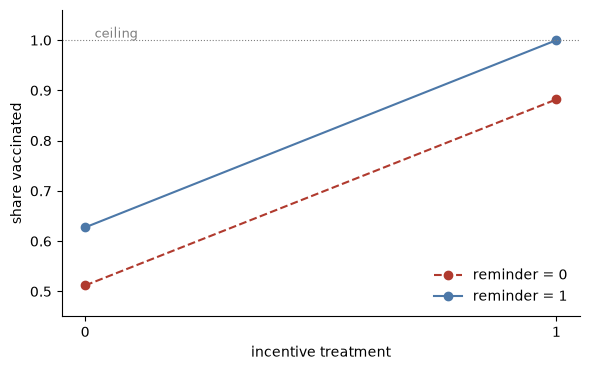

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.8))

for rem, colour, style in [(0, "#B03A2E", "o--"), (1, "#4C78A8", "o-")]:
    ys = [m[(0, rem)], m[(1, rem)]]
    ax.plot([0, 1], ys, style, color=colour, label=f"reminder = {rem}")

ax.axhline(1.0, color="grey", lw=0.8, ls=":")
ax.text(0.02, 1.005, "ceiling", color="grey", fontsize=9)
ax.set_xticks([0, 1])
ax.set_ylim(0.45, 1.06)
ax.set_xlabel("incentive treatment")
ax.set_ylabel("share vaccinated")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Three things map onto three coefficients:

- the **vertical gap** between the lines is the reminder effect, about 11 points
- the **slope** of each line is the incentive effect, visibly much steeper than the gap
- whether the lines are **parallel** is the interaction, and they are almost parallel

The plot shows one thing the coefficient table does not: the upper line hits the ceiling at x = 1. It could not have risen further, which is why the lines had to come out nearly parallel.

---

## Beyond the exercise · the lecture's own examples

### Example 9.1 · gym and learning diary

In [15]:
f = pd.read_csv(DATA / "lecture9_academic_performance.csv")
print(f.shape)
print(cells(f, ["D_gym", "D_diary"], "Y"))
print(f"\nME(gym)   = {main_effect(f, 'D_gym', 'Y'):.4f}   slide: 21.8")
print(f"ME(diary) = {main_effect(f, 'D_diary', 'Y'):.4f}   slide: 28.0")

(1000, 9)
               size    mean
D_gym D_diary              
0     0         250  126.80
      1         250  147.04
1     0         250  140.84
      1         250  176.62

ME(gym)   = 21.8100   slide: 21.8
ME(diary) = 28.0100   slide: 28.0


250 per cell, perfectly balanced, and both main effects reproduce the slides.

### Slide 7 writes the diary fraction with the wrong cells

The printed line is (176.6 + 126.8)/2 − (147.0 + 140.8)/2 = 161.8 − 133.8 = 28.0. The two totals and the answer are right. The fraction above them is not.

In [16]:
print(f"as printed : {(176.6+126.8)/2:6.1f} - {(147.0+140.8)/2:6.1f} = {(176.6+126.8)/2-(147.0+140.8)/2:5.1f}")
print(f"as correct : {(176.6+147.0)/2:6.1f} - {(140.8+126.8)/2:6.1f} = {(176.6+147.0)/2-(140.8+126.8)/2:5.1f}")
print("slide prints the result as 161.8 - 133.8 = 28.0")

as printed :  151.7 -  143.9 =   7.8
as correct :  161.8 -  133.8 =  28.0
slide prints the result as 161.8 - 133.8 = 28.0


The cells 126.8 and 147.0 have been swapped between the numerators. Reproducing the printed fraction gives 7.8, with no way to tell which number to trust.

### Interaction and the regression

In [17]:
y = f.groupby(["D_gym", "D_diary"])["Y"].mean()
print(f"gym effect with diary    = {y[(1, 1)] - y[(0, 1)]:.4f}   slide: 29.6")
print(f"gym effect without diary = {y[(1, 0)] - y[(0, 0)]:.4f}   slide: 14.0")
print(f"INT                      = {(y[(1, 1)] - y[(0, 1)]) - (y[(1, 0)] - y[(0, 0)]):.4f}   slide: 15.6")
print()
m2 = fit("Y ~ D_diary * D_gym", f)

gym effect with diary    = 29.5800   slide: 29.6
gym effect without diary = 14.0400   slide: 14.0
INT                      = 15.5400   slide: 15.6

                  est        se          t         p
Intercept      126.80  1.722742  73.603595  0.000000
D_diary         20.24  2.436325   8.307594  0.000000
D_gym           14.04  2.436325   5.762778  0.000000
D_diary:D_gym   15.54  3.445484   4.510252  0.000007

residual se = 27.2389 on 996 df
R2 = 0.3088   adj = 0.3067   F = 148.32


Matches slide 14 to the digit, coefficients and standard errors alike.

### The coefficient is not the main effect

`D_gym` = 14.04 is the gym effect **at diary = 0**, not ME(gym) = 21.81. The two differ by half the interaction, and coincide only when the interaction is zero.

In [18]:
fpm = f.assign(A=np.where(f.D_gym == 1, 1, -1), B=np.where(f.D_diary == 1, 1, -1))
mpm = smf.ols("Y ~ A * B", data=fpm).fit()

comparison = pd.DataFrame(
    {
        "0/1 coding": [m2.params["Intercept"], m2.params["D_gym"], m2.params["D_diary"],
                       m2.params["D_diary:D_gym"]],
        "+-1 coding": [mpm.params["Intercept"], mpm.params["A"], mpm.params["B"], mpm.params["A:B"]],
    },
    index=["intercept", "beta_gym", "beta_diary", "beta_interaction"],
)
print(comparison.round(4))
print(f"\n0/1:  beta_gym + beta_int/2 = {m2.params['D_gym'] + m2.params['D_diary:D_gym']/2:.4f}")
print(f"+-1:  2 * beta_A            = {2 * mpm.params['A']:.4f}")
print(f"the main effect             = {main_effect(f, 'D_gym', 'Y'):.4f}")
print(f"\n+-1 intercept is the grand mean: {f.Y.mean():.4f}")
print(f"+-1 interaction is a quarter of the 0/1 one: 4 * {mpm.params['A:B']:.4f} = {4*mpm.params['A:B']:.4f}")

                  0/1 coding  +-1 coding
intercept             126.80     147.825
beta_gym               14.04      10.905
beta_diary             20.24      14.005
beta_interaction       15.54       3.885

0/1:  beta_gym + beta_int/2 = 21.8100
+-1:  2 * beta_A            = 21.8100
the main effect             = 21.8100

+-1 intercept is the grand mean: 147.8250
+-1 interaction is a quarter of the 0/1 one: 4 * 3.8850 = 15.5400


Under ±1 coding the intercept becomes the grand mean and 2β_A is the main effect directly, with no correction. That orthogonality is the real reason the ±1 notation exists, beyond the convenience shown on slide 17.

### Example 9.2 · higher-order designs

In [19]:
print(cells(f, ["D_gym", "D_diary", "D_sleep"], "Y"))
print("\nslide 21: 115.7 137.9 127.2 166.8 124.3 157.4 154.3 199.0\n")
for col in ["D_gym", "D_diary", "D_sleep"]:
    print(f"ME({col:8s}) = {main_effect(f, col, 'Y'):.4f}")

                       size    mean
D_gym D_diary D_sleep              
0     0       0         125  115.68
              1         125  137.92
      1       0         125  127.24
              1         125  166.84
1     0       0         125  124.28
              1         125  157.40
      1       0         125  154.28
              1         125  198.96

slide 21: 115.7 137.9 127.2 166.8 124.3 157.4 154.3 199.0

ME(D_gym   ) = 21.8100
ME(D_diary ) = 28.0100
ME(D_sleep ) = 34.9100


125 per cell. The gym and diary main effects are **unchanged** from the 2 × 2 analysis, 21.81 and 28.01, which is what balance buys: adding a third factor does not disturb the first two.

### The cube plot

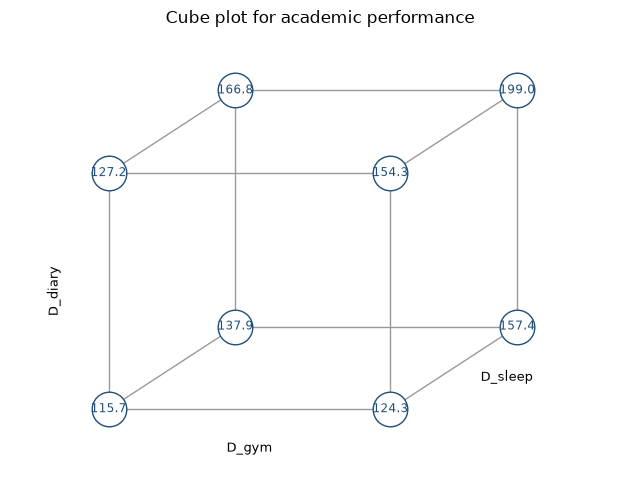

In [20]:
corners = f.groupby(["D_gym", "D_diary", "D_sleep"])["Y"].mean()
proj = lambda x, y, z: (x + 0.45 * z, y + 0.35 * z)

fig, ax = plt.subplots(figsize=(6.5, 5))
pts = {}
for (g, d, s), val in corners.items():
    pts[(g, d, s)] = proj(g, d, s)

for a in pts:
    for b in pts:
        if sum(abs(np.array(a) - np.array(b))) == 1 and a < b:
            ax.plot(*zip(pts[a], pts[b]), color="#999999", lw=1, zorder=1)

for key, (px, py) in pts.items():
    ax.scatter(px, py, s=620, facecolor="white", edgecolor="#1f4e79", zorder=2)
    ax.text(px, py, f"{corners[key]:.1f}", ha="center", va="center", fontsize=8.5,
            color="#1f4e79", zorder=3)

ax.set_title("Cube plot for academic performance")
ax.text(0.5, -0.18, "D_gym", ha="center", fontsize=9)
ax.text(-0.22, 0.5, "D_diary", va="center", rotation=90, fontsize=9)
ax.text(1.32, 0.12, "D_sleep", fontsize=9)
ax.set_xlim(-0.35, 1.85)
ax.set_ylim(-0.3, 1.6)
ax.axis("off")
plt.tight_layout()
plt.show()

Each edge joins two cells differing in exactly one treatment, so an edge length is that treatment's effect holding the other two fixed. Comparing parallel edges reads an interaction straight off the picture.

### The full model

In [21]:
m3 = fit("Y ~ D_diary * D_gym * D_sleep", f)

                          est        se          t         p
Intercept              115.68  1.833253  63.100951  0.000000
D_diary                 11.56  2.592611   4.458825  0.000009
D_gym                    8.60  2.592611   3.317119  0.000943
D_diary:D_gym           18.44  3.666506   5.029312  0.000001
D_sleep                 22.24  2.592611   8.578225  0.000000
D_diary:D_sleep         17.36  3.666506   4.734753  0.000003
D_gym:D_sleep           10.88  3.666506   2.967403  0.003075
D_diary:D_gym:D_sleep   -5.80  5.185222  -1.118563  0.263597

residual se = 20.4964 on 992 df
R2 = 0.6102   adj = 0.6075   F = 221.85


Matches slide 24. Eight cells, eight coefficients, again an exact re-parameterisation.

The three two-way interactions are all significant and sizeable, 18.44, 17.36 and 10.88 against main terms of 8 to 22. Dropping them would not remove their content, it would push it into the terms that remain, so the survivors would stop estimating what their names say.

The three-way term is **not** significant at p = 0.26, which is a fact about this dataset and not a licence to drop it. Muralidharan, Romero and Wüthrich (2025) argue the specification should follow the design rather than the p-values, because dropping a term for failing a threshold is a model selection step that invalidates the inference on everything left in.

Note the standard errors against the 2 × 2 model: 2.59 versus 2.44 on the main terms, and 5.19 on the triple interaction. A 2^k design splits the sample into 2^k cells, so every added factor halves the per-cell n, and the highest-order term is usually the first to lose significance.